## 1. Load an Example Image and Road Mask

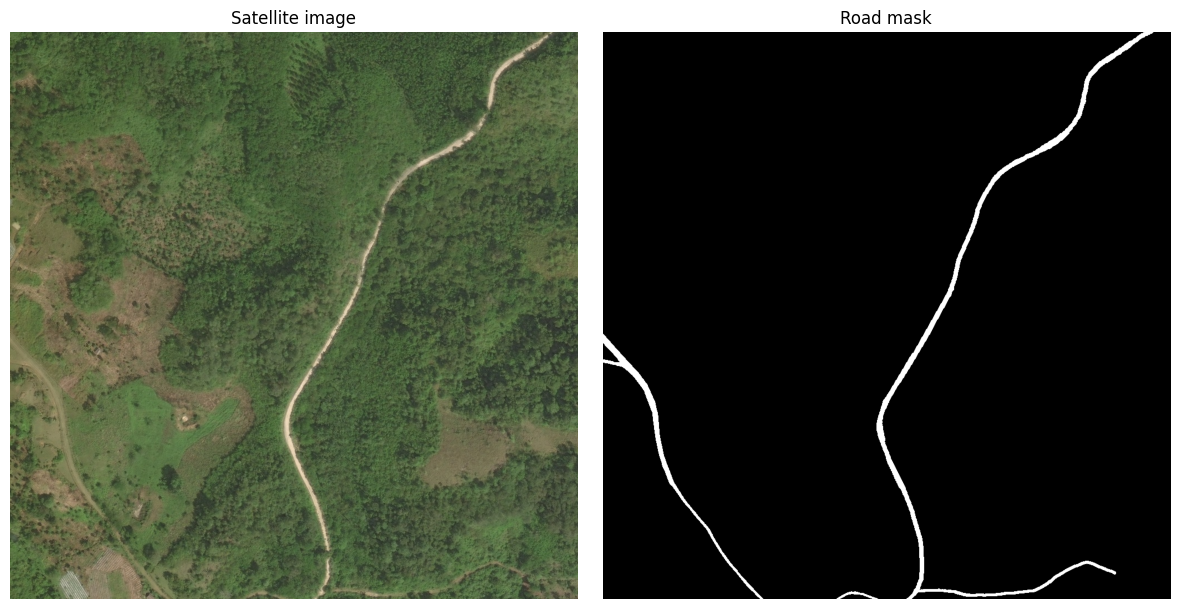

In [1]:
# Load one labeled image-and-mask pair for the augmentation demonstration.
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image


DATASET_DIR = Path(
    "/kaggle/input/datasets/balraj98/"
    "deepglobe-road-extraction-dataset"
)

train_dir = DATASET_DIR / "train"

# Keep only satellite images with a matching road mask.
image_paths = sorted(train_dir.glob("*_sat.jpg"))

pairs = [
    (path, path.with_name(path.name.replace("_sat.jpg", "_mask.png")))
    for path in image_paths
    if path.with_name(
        path.name.replace("_sat.jpg", "_mask.png")
    ).exists()
]

assert pairs, "No matching image-and-mask pairs found."

image_path, mask_path = pairs[0]

with Image.open(image_path) as im:
    image = np.array(im.convert("RGB"))

with Image.open(mask_path) as im:
    mask_gray = np.array(im.convert("L"))

assert image.shape[:2] == mask_gray.shape, "Image and mask sizes differ."

fig, axes = plt.subplots(1, 2, figsize=(12, 6))

axes[0].imshow(image)
axes[0].set_title("Satellite image")

axes[1].imshow(mask_gray, cmap="gray", vmin=0, vmax=255)
axes[1].set_title("Road mask")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

## 2. Paired Image and Mask Transformations

In [2]:
# Convert the road mask to binary values:
# 0 = background, 1 = road.
mask = (mask_gray > 127).astype(np.uint8)


def transform_pair(image, mask, horizontal=False,
                   vertical=False, rotations=0):
    """
    Apply identical transformations to an image and its mask.
    Each rotation is 90 degrees counterclockwise.
    """
    aug_image = image.copy()
    aug_mask = mask.copy()

    if horizontal:
        aug_image = np.flip(aug_image, axis=1)
        aug_mask = np.flip(aug_mask, axis=1)

    if vertical:
        aug_image = np.flip(aug_image, axis=0)
        aug_mask = np.flip(aug_mask, axis=0)

    aug_image = np.rot90(aug_image, k=rotations, axes=(0, 1))
    aug_mask = np.rot90(aug_mask, k=rotations, axes=(0, 1))

    return (
        np.ascontiguousarray(aug_image),
        np.ascontiguousarray(aug_mask)
    )

## 3. Visual Verification of Transformations

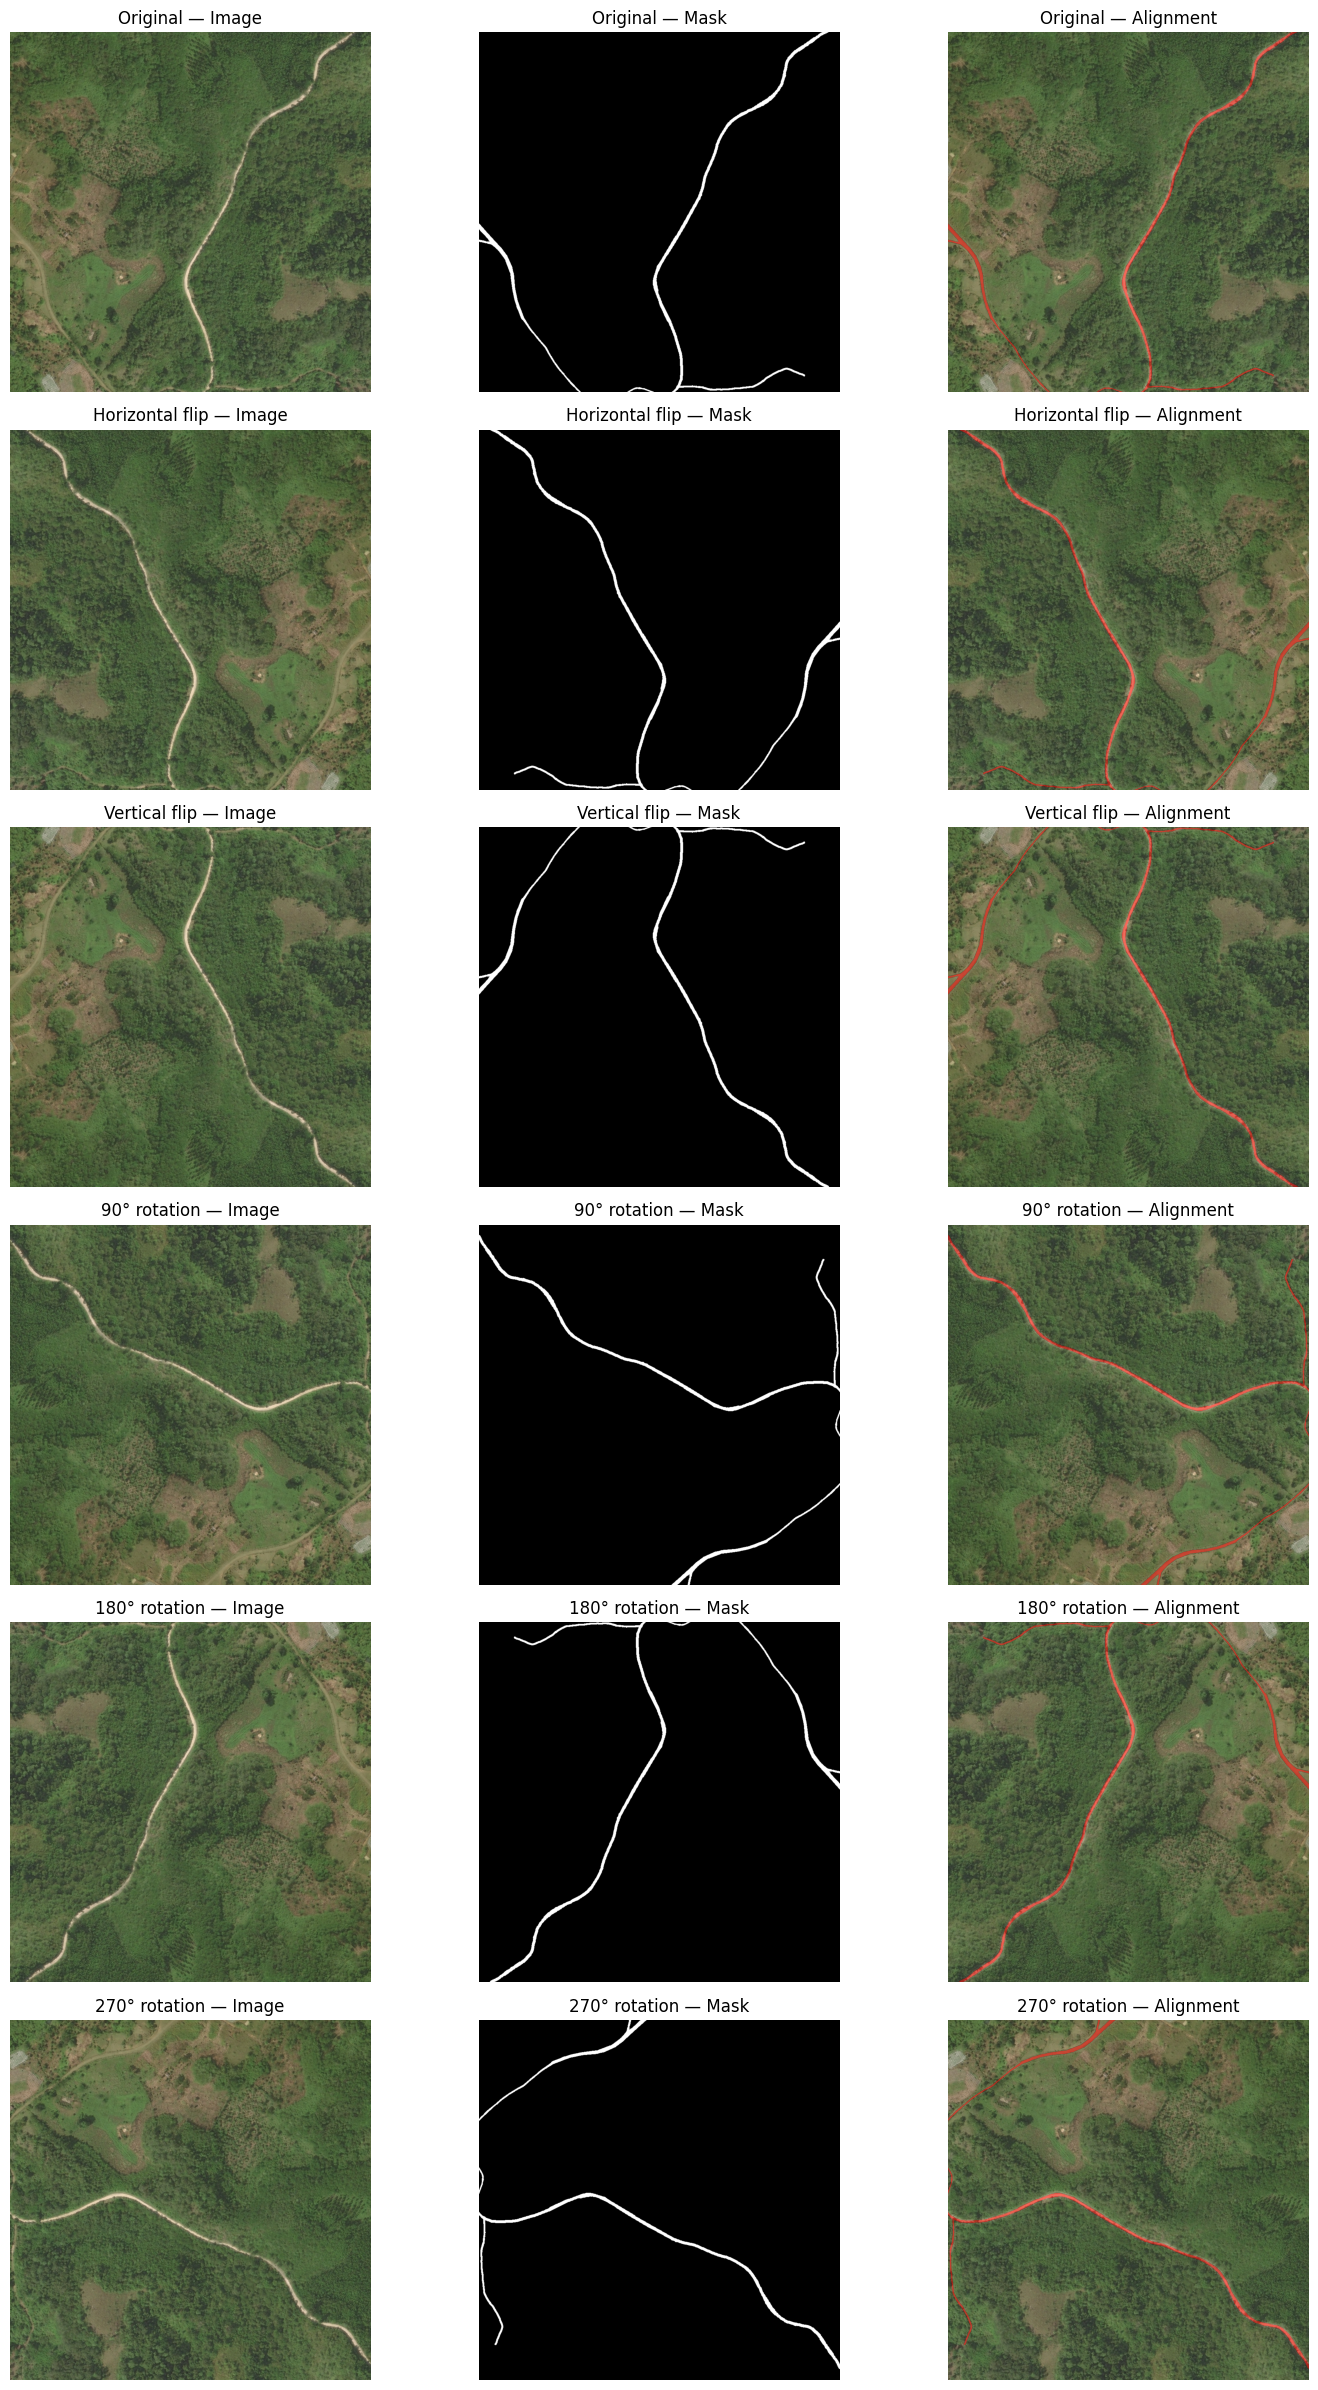

In [3]:
# Compare the original pair with each augmentation.
examples = [
    ("Original", {}),
    ("Horizontal flip", {"horizontal": True}),
    ("Vertical flip", {"vertical": True}),
    ("90° rotation", {"rotations": 1}),
    ("180° rotation", {"rotations": 2}),
    ("270° rotation", {"rotations": 3}),
]

fig, axes = plt.subplots(6, 3, figsize=(15, 24))

for row, (name, settings) in enumerate(examples):
    aug_image, aug_mask = transform_pair(image, mask, **settings)

    # Check matching dimensions and preserved mask values.
    assert aug_image.shape[:2] == aug_mask.shape
    assert set(np.unique(aug_mask)).issubset({0, 1})
    assert aug_mask.sum() == mask.sum()

    axes[row, 0].imshow(aug_image)
    axes[row, 0].set_title(f"{name} — Image")

    axes[row, 1].imshow(aug_mask, cmap="gray", vmin=0, vmax=1)
    axes[row, 1].set_title(f"{name} — Mask")

    # Place the road mask over the image in transparent red.
    overlay = np.zeros((*aug_mask.shape, 4), dtype=float)
    overlay[aug_mask == 1] = [1, 0, 0, 0.5]

    axes[row, 2].imshow(aug_image)
    axes[row, 2].imshow(overlay)
    axes[row, 2].set_title(f"{name} — Alignment")

    for ax in axes[row]:
        ax.axis("off")

plt.tight_layout()
plt.show()

## 4. Random Augmentation for Training

In [4]:
def random_augment_pair(image, mask, rng):
    """Randomly transform a matching image and binary mask."""
    return transform_pair(
        image,
        mask,
        horizontal=rng.random() < 0.5,
        vertical=rng.random() < 0.5,
        rotations=int(rng.integers(0, 4))
    )


# Create the generator once, outside the training loop.
rng = np.random.default_rng(42)

## 5. Verification on Multiple Examples

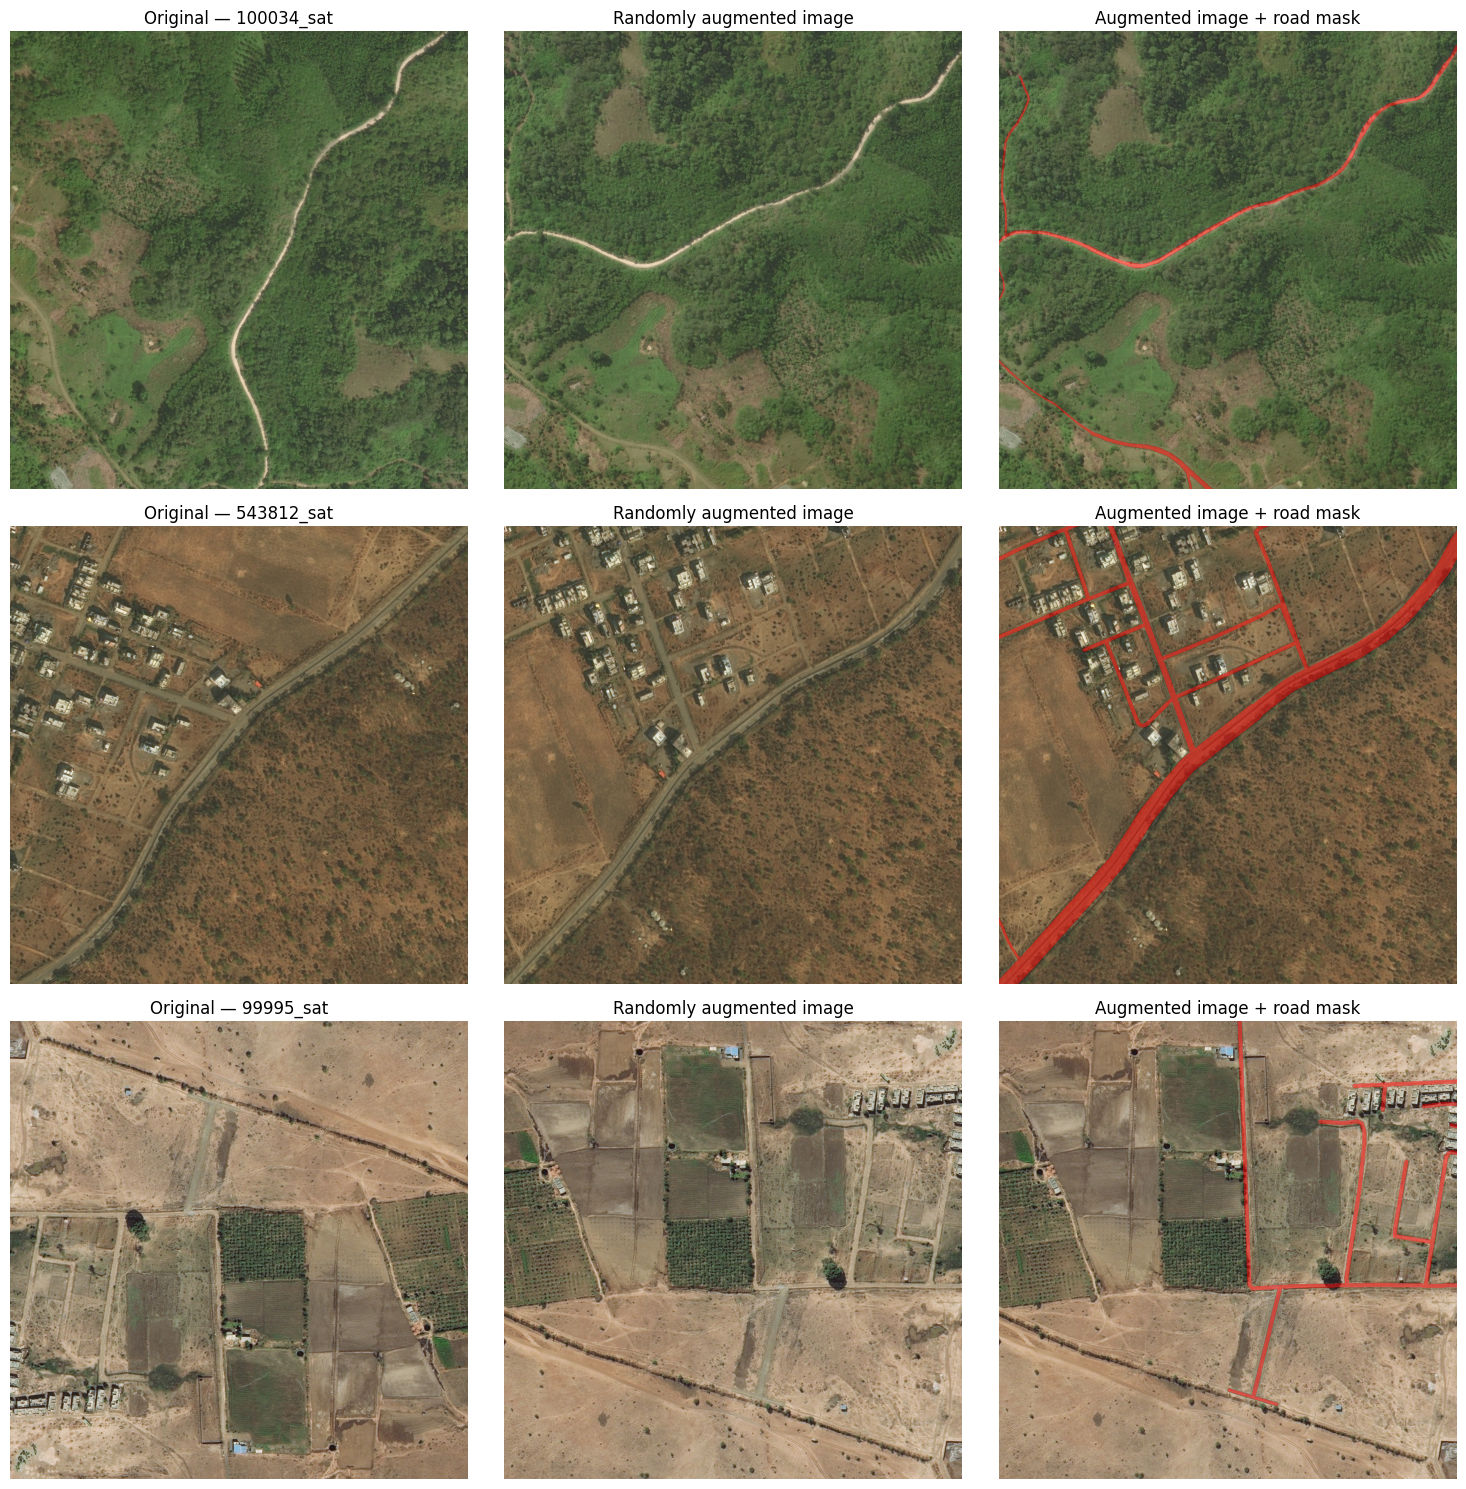

All three pairs passed the dimension and mask checks.


In [5]:
# Demonstrate random augmentation on three different labeled pairs.
demo_indices = [0, len(pairs) // 2, len(pairs) - 1]
demo_rng = np.random.default_rng(42)

fig, axes = plt.subplots(3, 3, figsize=(15, 15))

for row, index in enumerate(demo_indices):
    image_path, mask_path = pairs[index]

    with Image.open(image_path) as im:
        demo_image = np.array(im.convert("RGB"))

    with Image.open(mask_path) as im:
        demo_mask = (
            np.array(im.convert("L")) > 127
        ).astype(np.uint8)

    assert demo_image.shape[:2] == demo_mask.shape

    aug_image, aug_mask = random_augment_pair(
        demo_image, demo_mask, demo_rng
    )

    assert aug_image.shape[:2] == aug_mask.shape
    assert set(np.unique(aug_mask)).issubset({0, 1})
    assert aug_mask.sum() == demo_mask.sum()

    axes[row, 0].imshow(demo_image)
    axes[row, 0].set_title(f"Original — {image_path.stem}")

    axes[row, 1].imshow(aug_image)
    axes[row, 1].set_title("Randomly augmented image")

    overlay = np.zeros((*aug_mask.shape, 4), dtype=float)
    overlay[aug_mask == 1] = [1, 0, 0, 0.5]

    axes[row, 2].imshow(aug_image)
    axes[row, 2].imshow(overlay)
    axes[row, 2].set_title("Augmented image + road mask")

    for ax in axes[row]:
        ax.axis("off")

plt.tight_layout()
plt.show()

print("All three pairs passed the dimension and mask checks.")

### Integration Notes

- Apply augmentation only to the team's final training split.
- Apply identical geometric transformations to each image and its mask.
- Input images have shape (H, W, 3); binary masks have shape (H, W).
- Horizontal and vertical flips each have a probability of 0.5.
- Rotation is selected uniformly from 0°, 90°, 180°, and 270°.
- Create the random generator once outside the training loop.
- The examples above demonstrate augmentation; no model has been trained.